# 02-ROS2开发环境搭建


## 1. 学习目标与资料范围

本篇对应课程《ROS环境搭建.pdf》，目标是建立一套可进入后续开发的 **Ubuntu 24.04 + ROS2 Jazzy** 环境，并能说明各安装步骤的作用。

课件共32页，已逐页核对页面预览。本篇整理1—31页的安装路线、虚拟机设置、Ubuntu安装、基础环境与ROS2安装验证；第32页为品牌结束页。图注标明原课件页码。

完成本篇后，应能做到：

1. 分清Windows宿主机、VMware与Ubuntu虚拟机的关系。
2. 创建虚拟机并安装Ubuntu 24.04。
3. 配置软件源、桌面集成工具、SSH与UTF-8环境。
4. 添加ROS软件仓库，安装Jazzy和开发工具。
5. 在新终端中启动小乌龟示例，定位常见安装问题。

**阅读方式：**以下Linux命令写在Markdown代码块中，供在Ubuntu终端操作；不是在Windows PowerShell或Notebook中直接运行的代码。本篇整理课件，没有替读者安装虚拟机，也未实际执行这些安装命令。文中“工程补充”与课件原始步骤作了区分。


## 2. 安装路线与版本对应关系

课件的安装顺序为：安装VMware → 创建Ubuntu虚拟机 → 安装Ubuntu 24.04 → 配置基础环境 → 安装ROS2 Jazzy → 运行示例。

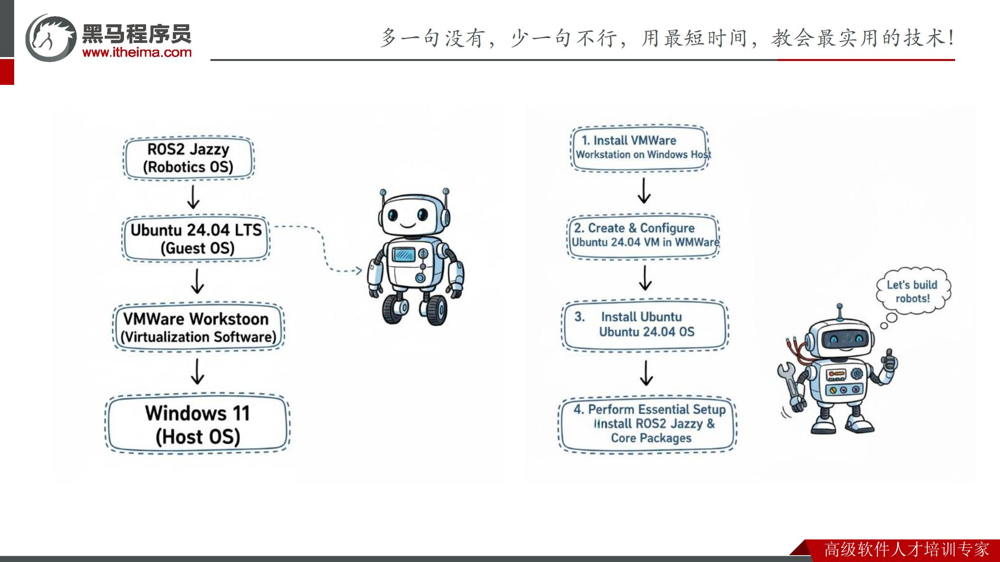

*原课件第5页：Windows宿主机、VMware、Ubuntu 24.04和ROS2 Jazzy的层次关系。*

| 组件 | 课程选用 | 作用 |
|---|---|---|
| 宿主机系统 | 图示为Windows 11 | 运行虚拟机软件，保存虚拟机文件 |
| 虚拟化软件 | VMware Workstation | 为Ubuntu提供虚拟CPU、内存、磁盘与网络 |
| 客体系统 | Ubuntu 24.04 LTS | 运行Linux工具与ROS2程序 |
| ROS发行版 | Jazzy | 提供本课程使用的机器人开发环境 |

**Ubuntu 24.04的发行代号是`noble`，ROS2发行版名是`jazzy`。**它们不是同一类版本号，后续分别出现在APT源配置包名称和ROS软件包名称中。

课件第4页说明采用Windows中运行Linux的课程路线。**工程补充：**这不表示ROS2只能在Linux运行；本课程选择Linux是为了统一开发和教学环境。实际ROS2平台支持仍依发行版和组件而定。

本篇命令围绕Ubuntu 24.04与Jazzy编写，不把其他Ubuntu版本或其他ROS发行版的安装步骤混入其中。


## 3. 安装VMware与准备Ubuntu镜像

课件第6—7页进入虚拟机环境搭建，给出VMware下载与运行安装程序的流程；第8页开始演示新建虚拟机。界面截图使用Workstation Pro 16，实际软件版本不同，按钮位置可能变化。

准备材料包括VMware安装程序、Ubuntu 24.04桌面版64位ISO，以及用于保存虚拟机的目录。Ubuntu镜像截图显示24.04.2，它属于24.04 LTS系列。

**工程补充：**VMware下载入口与账户流程可能变化，可从[VMware官方产品入口](https://www.vmware.com/products/desktop-hypervisor/workstation-and-fusion)查找；Ubuntu镜像可从[Ubuntu官方桌面下载页](https://ubuntu.com/download/desktop)获取。这里是查阅入口，不表示已下载或测试当前安装包。

镜像是安装介质，虚拟磁盘是安装后的系统存储，二者不能混为一谈。VMware创建的虚拟机配置文件和磁盘文件也需要保留。

启动虚拟机前，可以检查宿主机是否支持并启用了硬件虚拟化。若软件提示VT-x、AMD-V等不可用，先根据具体提示排查宿主机与虚拟化软件配置，而不是反复修改ROS安装命令。

本篇只整理安装知识，不修改当前电脑的系统设置。


## 4. 新建虚拟机：名称、位置、镜像与账户

课件第8—10页的主要操作如下：

1. 在VMware“文件”菜单选择“新建虚拟机”，或使用`Ctrl+N`。
2. 示例选择“自定义（高级）”，跟随向导继续。
3. 设置虚拟机名称与保存位置。课件示例名称为`itheima_ros`，路径为`D:\VmwareMachines\itheima_ros`。
4. 在安装来源中选择Ubuntu ISO镜像，确认客体系统识别为Ubuntu 64位。
5. 如果向导进入“简易安装信息”，填写姓名、Linux用户名及密码。

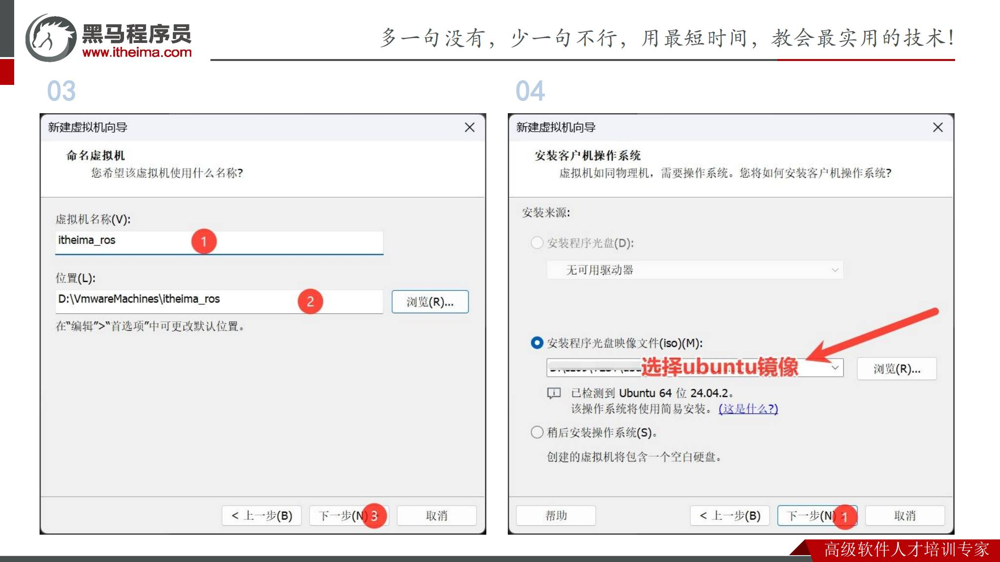

*原课件第9页：虚拟机名称、保存目录与Ubuntu镜像选择。*

**三种名称要分清：**VMware的虚拟机名称用于区分虚拟机；Ubuntu计算机名用于标识Linux主机；Linux用户名用于登录和拥有个人文件。它们可以相似，但不是同一设置。

课件后续还展示Ubuntu交互式安装。因此应按实际界面操作：若简易安装没有接管流程，就按第7节手动完成安装；若系统已经自动安装完成，就直接检查安装结果，不必为了凑齐截图重复安装。

账户与目录可以按自己的情况设置，后续命令中的个人路径也要对应实际用户名。


## 5. CPU、内存与网络配置

课件第11页要求根据电脑配置选择处理器与内存，标注内存至少4GB；示例内存为8192MB。处理器截图为2个处理器、每个8核，共16个虚拟CPU，这只是示例。

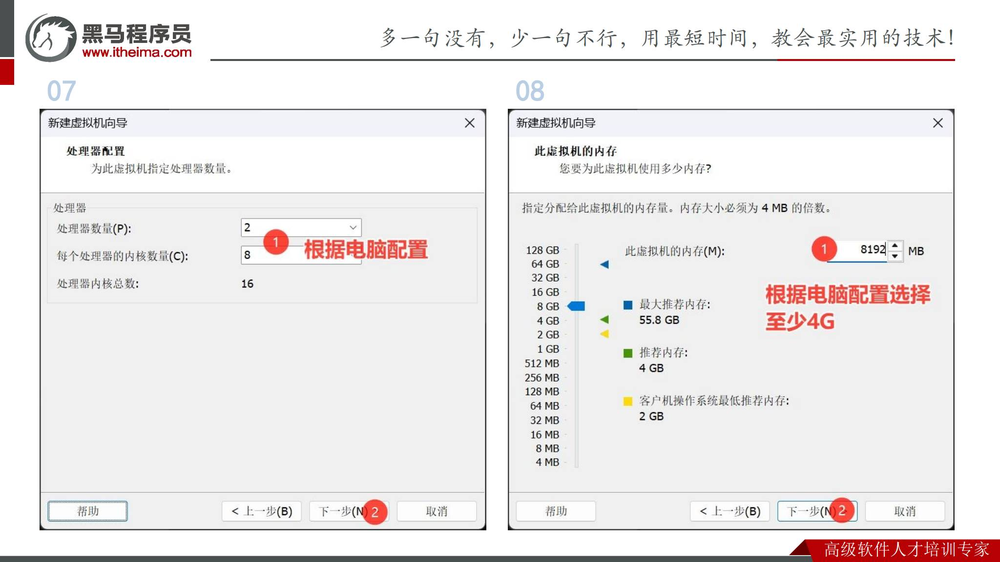

*原课件第11页：资源应根据宿主机配置分配，不应机械照抄示例数值。*

**工程补充：**虚拟机分配的资源仍由宿主机提供，应给Windows与其他应用留出空间。入门实践可依据实际硬件从适量vCPU和4—8GB内存开始，再观察负载调整；运行视觉或仿真时可能需要更多资源。不能认为分配越多就一定越快。

课件第12页选择 **NAT网络**。

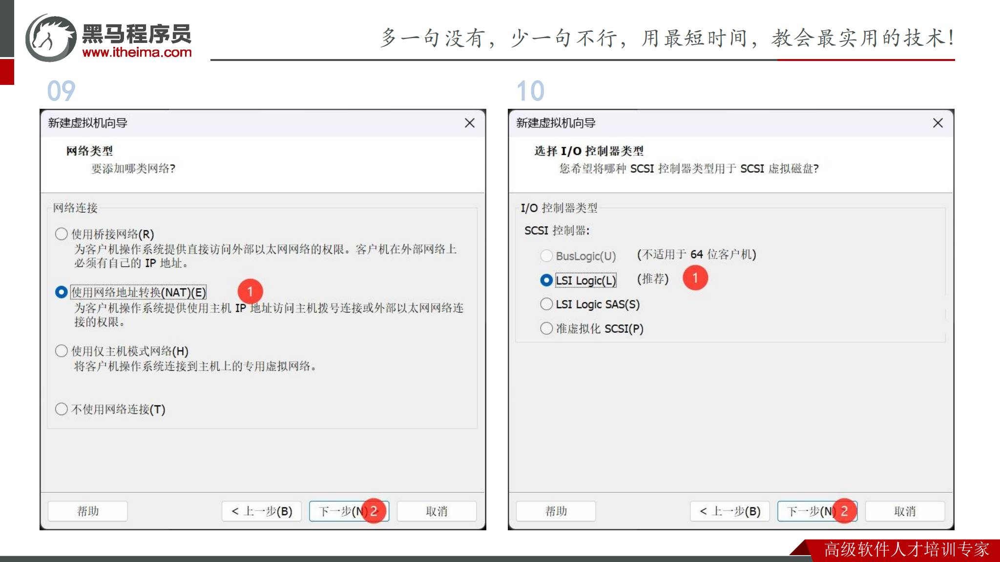

*原课件第12页：NAT网络与推荐的LSI Logic控制器。*

| 网络模式 | 含义 | 本阶段使用考虑 |
|---|---|---|
| NAT | 虚拟机通过宿主机网络访问外部 | 适合下载软件和进行单机学习 |
| 桥接 | 虚拟机作为局域网中的一台设备 | 后续与实体机器人通信时可按网络条件评估 |
| 仅主机 | 主要用于宿主机与虚拟机之间通信 | 默认不提供同样的外网访问方式 |

**工程补充：**NAT能联网，不代表局域网中其他设备都能直接发现虚拟机。ROS2跨设备通信还涉及路由、发现机制与防火墙等因素；本篇先完成单机环境，不把NAT视为所有机器人网络场景的固定选择。


## 6. 控制器、虚拟磁盘与创建完成

课件第12—15页继续设置虚拟硬件：

1. I/O控制器选择截图推荐的LSI Logic。
2. 虚拟磁盘类型选择SCSI。
3. 选择“创建新虚拟磁盘”。
4. 课件示例最大容量30GB，并选择拆分为多个文件。
5. 确认磁盘文件名与配置摘要，完成虚拟机创建。

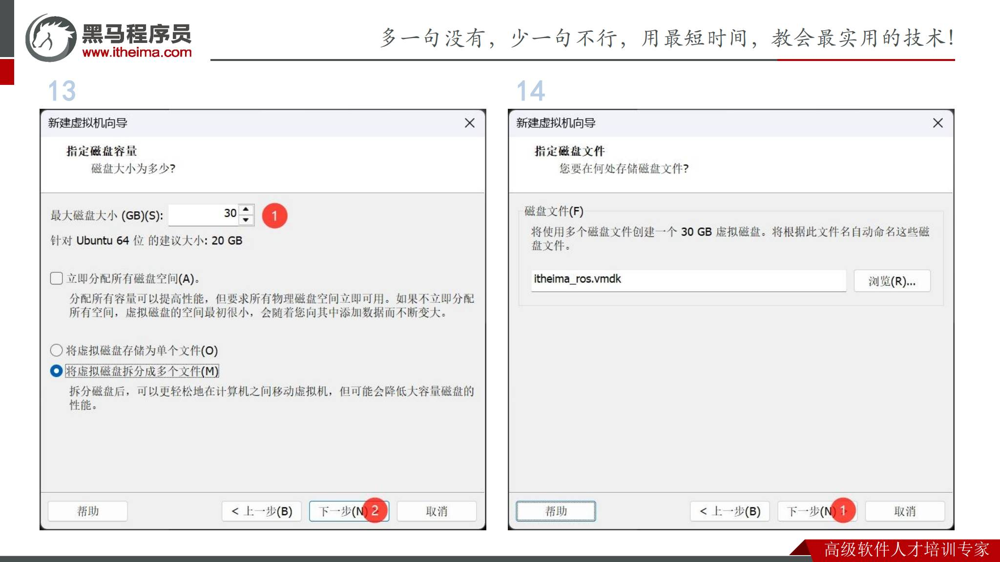

*原课件第14页：30GB最大容量、多个文件存储及磁盘文件名。*

**工程补充：**30GB是课件示例，不是机器人开发的通用容量要求。系统更新、ROS软件包、编译产物、仿真模型和图像数据会持续占用空间；有条件时可以预留更大的虚拟磁盘容量，并检查宿主机实际剩余空间。

“最大容量”与“立即占用空间”不同。按需增长的虚拟磁盘通常随着写入数据逐渐增大；如果选择立即分配全部空间，宿主机占用方式也会不同。拆分多个文件不会让Ubuntu看见多个独立磁盘。

课件第15页还有侧通道缓解提示。它属于VMware配置提示，不是ROS安装失败。先阅读具体提示并确认虚拟机能正常启动，不把它与Ubuntu软件包错误混在一起处理。


## 7. Ubuntu 24.04交互式安装

课件第16页进入Ubuntu环境搭建，第17—23页展示安装界面。可以按以下阶段理解，界面文字依镜像版本可能略有差别。

| 阶段 | 课件所示选择或操作 |
|---|---|
| 语言 | 选择中文（简体） |
| 辅助功能 | 根据需要设置后继续 |
| 键盘 | 确认键盘布局 |
| 网络 | 使用有线连接 |
| 安装器更新 | 截图选择跳过更新后继续 |
| 安装或试用 | 选择安装Ubuntu |
| 安装方式 | 选择交互安装 |
| 应用集合 | 选择默认集合 |
| 第三方软件 | 截图未勾选图形/Wi-Fi及媒体支持选项 |
| 磁盘 | 在新建虚拟磁盘上安装Ubuntu |
| 账户 | 填写姓名、计算机名、用户名和密码 |
| 时区 | 截图为上海、Asia/Shanghai |
| 最终确认 | 阅读摘要，确认后开始安装 |

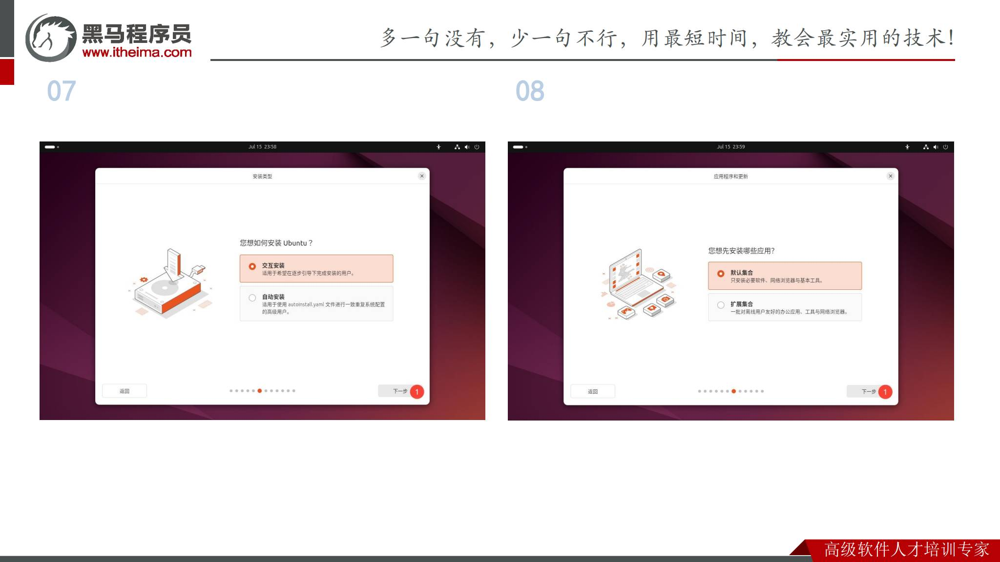

*原课件第20页：交互安装与默认应用集合。*

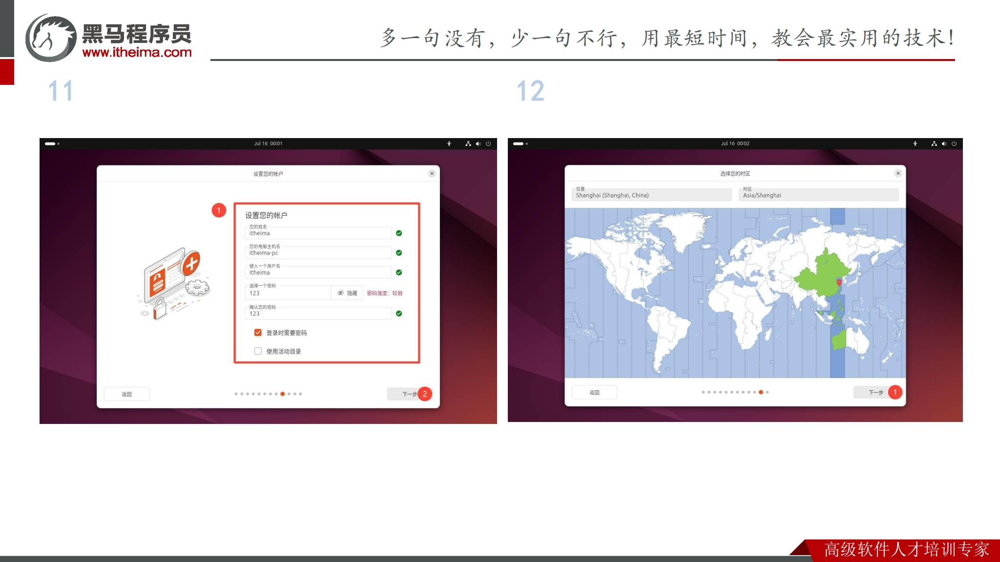

*原课件第22页：创建账户并设置时区。*

**工程补充：**第21页“擦除磁盘并安装Ubuntu”针对的是本流程新建的空白虚拟磁盘。仅在确认安装器操作对象为该虚拟磁盘时使用；如果是在实体机、已有数据的虚拟机或直通物理磁盘上安装，应按实际分区与数据情况处理。

课件未要求安装虚拟机中的NVIDIA驱动，不应因为宿主机有独立显卡就机械勾选客体驱动。后续视觉或仿真需求再依据实际虚拟硬件能力评估。


## 8. 安装结束、重启与系统确认

课件第23页展示安装摘要与进度，第24页显示Ubuntu 24.04.2 LTS安装完成，选择立即重启。若重启时提示移除安装介质，按提示断开ISO，再进入已安装的系统。

登录后先确认系统确实从虚拟磁盘启动，而不是再次进入ISO的试用环境。以下是**工程补充的只读检查命令**：

```bash
cat /etc/os-release
uname -m
df -h /
free -h
ip -brief address
```

它们分别用于查看发行版、体系结构、根目录所在文件系统空间、内存和网络地址。Ubuntu版本应属于24.04系列，发行代号应为`noble`。本课程普通PC虚拟机通常为`x86_64`。

课件第24页右侧还展示VMware不可恢复错误：`(vcpu-12)`、`Exception 0xc0000005 (access violation)`，并给出`vmware.log`位置。

**工程补充：**该截图只能证明出现了虚拟机层异常，不能单凭截图判断唯一原因。可先记录完整错误和日志，确认VMware与宿主机兼容情况，检查资源配置，并在关机后调整再重试。截图没有提供确定修复步骤，本篇不把某项修改写成必然有效的解决方案。

先保证Ubuntu能够稳定启动和登录，再进入APT与ROS安装，可以更清楚地区分故障层次。


## 9. 修改Ubuntu软件源与更新系统

课件第25页在“软件和更新”中选择阿里镜像源，然后重新载入软件包信息。

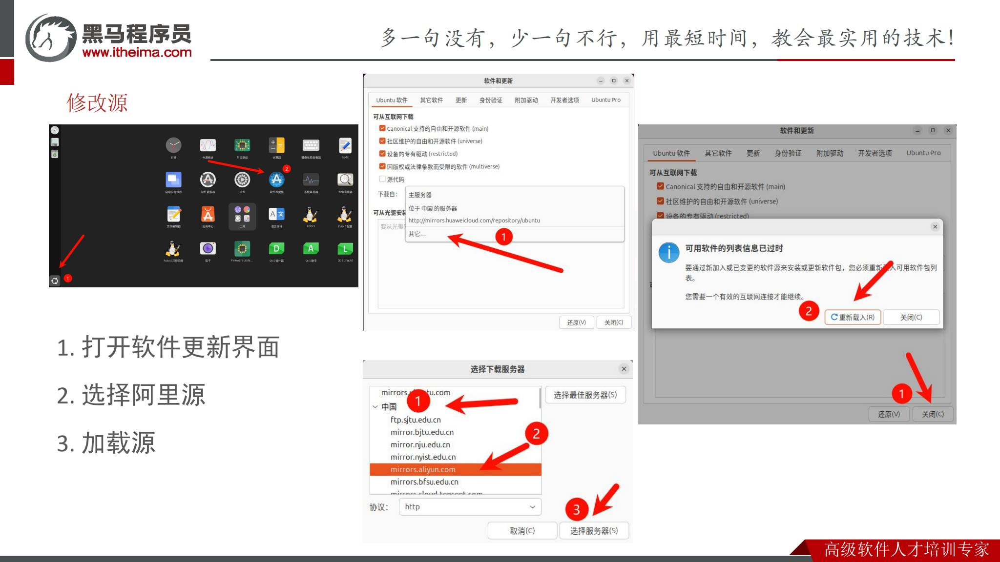

*原课件第25页：选择下载服务器，应用更改并重新载入。*

软件源可以理解为APT查询和下载软件包的仓库地址。镜像源用于改善访问条件，不应通过更换Ubuntu发行代号来“解决下载慢”。本课程需要保持`noble`对应的仓库配置。

课件第26页的系统更新命令：

```bash
sudo apt update
sudo apt upgrade
```

| 命令 | 作用 |
|---|---|
| `apt update` | 更新本地软件包索引，获知仓库有哪些版本 |
| `apt upgrade` | 按软件包管理规则升级已安装软件 |

**工程补充：**`update`成功不等于所有软件已经升级。若索引更新报错，先处理网络、DNS或源配置，再继续安装后续软件。Ubuntu镜像源与ROS软件仓库是两件事：选择Ubuntu镜像不会自动添加ROS2仓库。

APT安装和升级通常会列出变更并等待确认；阅读结果，按实际提示操作。若提示需要重启，可在更新完成后重启，再继续安装。


## 10. 桌面集成工具与OpenSSH

### 10.1 解决虚拟机显示与全屏问题

课件第26页安装桌面版VMware集成工具并重启：

```bash
sudo apt install open-vm-tools-desktop
sudo reboot
```

`open-vm-tools-desktop`提供桌面环境与VMware的集成功能，常用于显示尺寸调整等。**工程补充：**还需要VMware客户端启用相应自动适应显示功能；安装后全屏仍异常时，再检查桌面会话、显示设置与客户端选项。

### 10.2 安装SSH服务

课件用于远程连接的步骤：

```bash
sudo apt install openssh-server
sudo service ssh restart
sudo systemctl enable ssh
```

| 操作 | 目的 |
|---|---|
| 安装`openssh-server` | 提供SSH服务端 |
| 重启`ssh`服务 | 让服务重新启动 |
| `enable ssh` | 设置服务随系统启动 |

**工程补充检查：**

```bash
systemctl status ssh --no-pager
ip -brief address
```

在Windows终端中，SSH连接的形式为`ssh 用户名@虚拟机IP`。把用户名与地址换成Ubuntu中的实际值；密码输入通常不会显示字符。

SSH能登录证明远程终端链路可用，但并不自动提供ROS图形程序显示。运行小乌龟示例时，本篇优先使用Ubuntu桌面中的终端。


## 11. 检查并配置UTF-8编码环境

课件第27页进入ROS2安装，第28页先检查本地编码：

```bash
locale
```

ROS2安装环境需要支持UTF-8。应查看`LANG`、`LC_*`等实际值，而不是要求所有人的语言都必须是英语；已有有效UTF-8环境时可以保留。

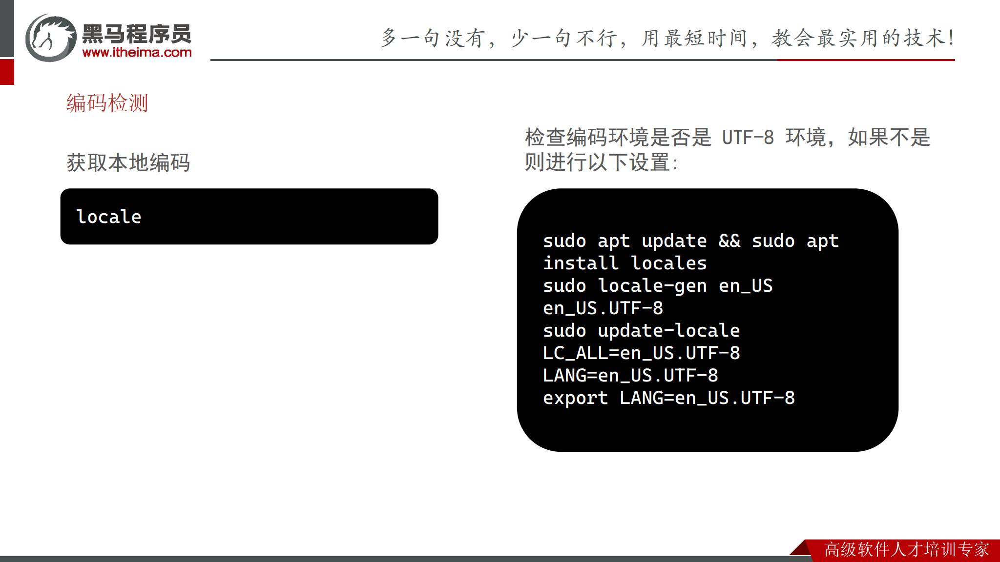

*原课件第28页：检查locale，必要时生成并设置UTF-8环境。*

如果当前不是有效UTF-8环境，课件配置路线整理为：

```bash
sudo apt update
sudo apt install locales
sudo locale-gen en_US en_US.UTF-8
sudo update-locale LC_ALL=en_US.UTF-8 LANG=en_US.UTF-8
export LANG=en_US.UTF-8
locale
```

`locale-gen`生成语言环境，`update-locale`修改系统默认设置，`export`影响当前Shell及其子进程。新登录会话才能完整反映系统默认值的改变，最后应重新检查结果。

**工程补充：**`locale`与`locale -a`不同：前者显示当前设置，后者列出系统已生成的语言环境。若出现“cannot change locale”，确认目标UTF-8环境已经生成，并检查是否有旧环境变量覆盖。


## 12. 启用Universe与添加ROS软件仓库

课件第29页先启用Ubuntu的Universe仓库：

```bash
sudo apt install software-properties-common
sudo add-apt-repository universe
```

接下来使用课程附件 **`ros2-apt-source_1.1.0.noble_all.deb`**。资料目录中存在该文件，本篇未下载安装包或检验其内容。这里依据课件说明安装方法。

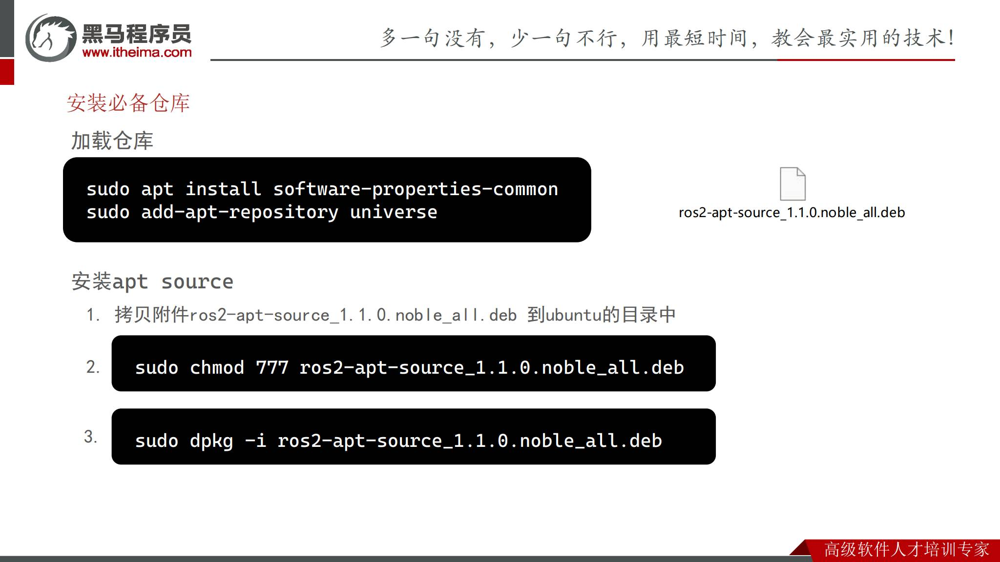

*原课件第29页：Universe与ros2-apt-source配置包。*

将文件复制到Ubuntu，并在文件所在目录打开终端。可以先用`pwd`确认当前目录，用`ls -l`确认文件名，再安装：

```bash
sudo dpkg -i ./ros2-apt-source_1.1.0.noble_all.deb
sudo apt update
```

课件使用`dpkg -i`安装源配置包。文件名中的`noble`对应Ubuntu 24.04，`all`是该包的体系结构字段，不能据此推断所有ROS核心包都与CPU架构无关。

**工程补充：课件中的`chmod 777`不是安装`.deb`的必要条件。**`.deb`是供包管理器读取的归档文件，不需要像脚本一样直接执行。因此本篇保留截图用于对照，操作路线省略该权限步骤；遇到文件不可读应检查实际权限与文件位置。

安装源配置包的作用是配置ROS仓库及相关信任信息，不等于已经安装完整ROS2。随后仍需刷新索引并安装Jazzy。

如果`dpkg`明确报依赖未满足，可依据错误信息使用`sudo apt --fix-broken install`修复，再重新检查。不要把修复命令作为每次安装都必做的步骤。


## 13. 安装ROS2 Jazzy与加载环境

### 13.1 安装工具和桌面环境

课件第30页先更新系统，再安装工具包与ROS桌面包：

```bash
sudo apt update
sudo apt upgrade
sudo apt install tar bzip2 wget -y
sudo apt install ros-dev-tools -y
sudo apt install ros-jazzy-desktop -y
```

`tar`和`bzip2`用于归档及解压，`wget`用于下载，`ros-dev-tools`提供ROS开发相关工具集合，`ros-jazzy-desktop`安装Jazzy桌面版软件集合。`-y`表示自动确认APT询问，执行前仍应理解要安装的内容。

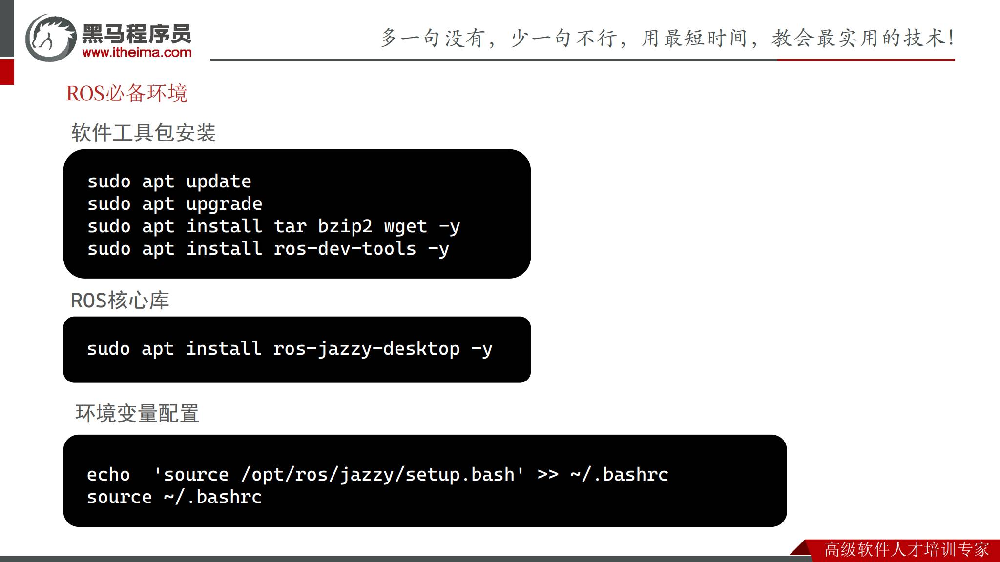

*原课件第30页：开发工具、Jazzy桌面包与环境变量配置。*

### 13.2 当前终端与以后新终端

安装后的环境脚本位于`/opt/ros/jazzy/setup.bash`。在Bash终端中运行：

```bash
source /opt/ros/jazzy/setup.bash
```

它把ROS的命令、库和包查找路径加入当前Shell环境。**安装软件**与**让终端加载环境**是不同步骤，因此软件已经装好时仍可能出现`ros2: command not found`。

课件把加载语句写入用户的`.bashrc`，使以后打开的交互式Bash终端自动加载：

```bash
echo 'source /opt/ros/jazzy/setup.bash' >> ~/.bashrc
source ~/.bashrc
```

**工程补充：**追加命令执行一次即可。重复执行会产生重复行；可先打开`.bashrc`检查是否已有该语句。`source ~/.bashrc`会执行整个文件，不只是最后一行。使用其他Shell时，需要采用匹配的环境脚本与启动配置文件。

后续项目还会加载工作空间的`install/setup.bash`，那是项目环境层；本篇先建立系统ROS环境，不提前替代工作空间构建步骤。


## 14. 验证安装：启动小乌龟与检查通信

课件第31页用小乌龟程序检验安装效果：在Ubuntu桌面终端运行：

```bash
ros2 run turtlesim turtlesim_node
```

出现蓝色背景的小乌龟窗口，说明当前终端能找到ROS2命令、turtlesim包并启动图形节点。

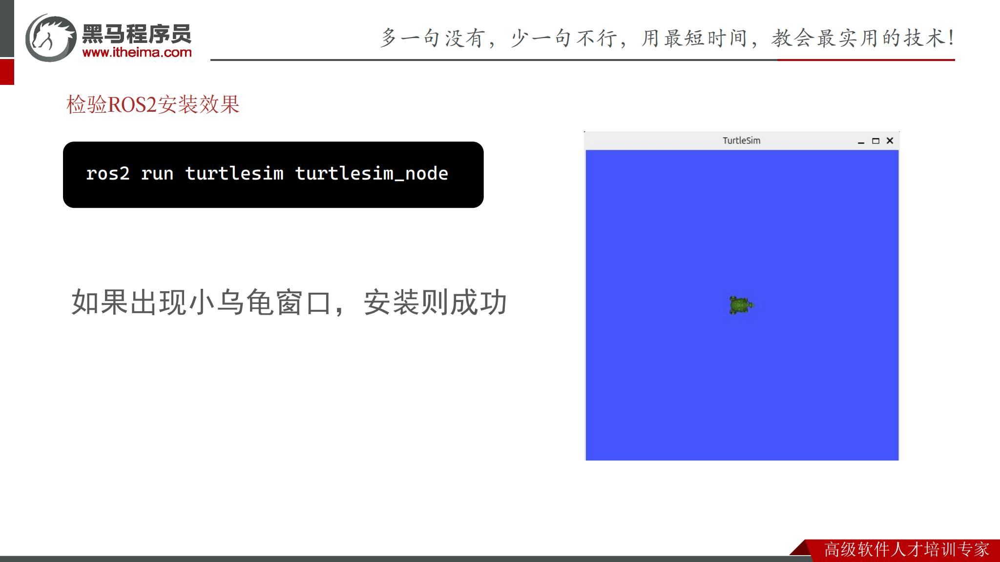

*原课件第31页：turtlesim_node与预期窗口。*

**工程补充：**窗口出现是基础启动验证，不能代表所有开发工具、硬件驱动或后续项目已经验证成功。可以分层检查，观察实际结果：

```bash
echo "$ROS_DISTRO"
command -v ros2
ros2 pkg prefix turtlesim
```

加载本课程环境后，`ROS_DISTRO`应为`jazzy`；另外两个命令分别确认CLI位置与包位置。

保持小乌龟窗口和第一个终端运行，在第二个已加载ROS环境的终端中执行：

```bash
ros2 node list
ros2 topic list
```

通常能看到`/turtlesim`节点及其相关话题。也可在第二个终端启动键盘控制：

```bash
ros2 run turtlesim turtle_teleop_key
```

按照终端提示使用方向键，并让键盘焦点保持在键盘控制终端。观察小乌龟是否移动，就能初步理解“一个节点发命令，另一个节点执行”的协作。结束程序可在对应终端按`Ctrl+C`。

这些额外验证是学习补充，不是本篇已在当前电脑成功运行的结果。第04篇再系统解释Topic通信。


## 15. 常见问题、安装检查表与复习

### 15.1 按故障层次排查

| 现象 | 优先检查 | 处理思路 |
|---|---|---|
| VMware无法启动或报vCPU异常 | 宿主机、虚拟化支持、VMware版本与日志 | 先解决虚拟机层问题，尚未涉及ROS |
| 系统重启又进入安装界面 | ISO连接与启动介质 | 确認已安装到虚拟磁盘，并从它启动 |
| Ubuntu下载软件失败 | 虚拟网卡、NAT、DNS、镜像地址 | 先恢复网络及正确仓库配置 |
| 找不到`ros-jazzy-desktop` | Ubuntu是否为noble、ROS源是否安装、索引是否更新 | 先检查版本和APT配置，再安装 |
| `.deb`文件不存在 | 当前目录、复制是否完成、文件名 | `.deb`应位于Ubuntu能访问的路径 |
| APT提示锁被占用 | 是否有软件更新或另一个APT进程 | 等待实际包管理操作完成，不直接删除锁文件 |
| `ros2: command not found` | `/opt/ros/jazzy/setup.bash`是否存在、是否source | 区分“未安装”和“未加载环境” |
| 小乌龟窗口无法打开 | 是否在Ubuntu桌面会话、图形环境与具体报错 | 先在桌面终端验证，SSH终端未必有显示环境 |
| ROS节点互相不可见 | 是否同一环境、域设置、网络与发现配置 | 先按本篇单机双终端方法排查 |
| 虚拟机变慢或安装磁盘不足 | CPU、内存、虚拟磁盘与宿主机空间 | 根据实际负载调整资源 |

### 15.2 环境完成检查表

- [ ] Ubuntu能从虚拟磁盘稳定启动，登录账户可用。
- [ ] 系统属于Ubuntu 24.04系列，版本代号为`noble`。
- [ ] 虚拟机能访问软件仓库，`apt update`没有未解决的错误。
- [ ] UTF-8环境有效。
- [ ] ROS源配置完成，Jazzy桌面包与开发工具已安装。
- [ ] 新开的Bash终端能使用`ros2`，环境发行版为`jazzy`。
- [ ] 小乌龟窗口能够启动，额外通信验证按需要完成。

这份检查表用于读者实际操作后的记录，本篇未勾选为已完成。

### 15.3 复习题与参考答案

1. **Windows、VMware、Ubuntu和ROS2是什么关系？**Windows是宿主机系统，VMware提供虚拟硬件，Ubuntu运行在虚拟机中，ROS2安装在Ubuntu中。
2. **为什么要匹配noble和jazzy？**前者指定Ubuntu版本，后者指定ROS发行版；仓库和软件包必须支持实际系统。
3. **`apt update`与`apt upgrade`有什么区别？**前者刷新索引，后者升级已安装的软件。
4. **换Ubuntu镜像源就能安装ROS2了吗？**不能，还需添加ROS仓库并安装相应软件包。
5. **安装`.deb`为什么不需要`chmod 777`？**它由包管理器读取，不作为可执行脚本直接运行。
6. **软件装好了，为什么新终端还可能找不到`ros2`？**终端可能尚未加载ROS环境脚本。
7. **小乌龟窗口出现说明什么？**基础CLI、包查找和图形节点启动可用，不代表整个机器人项目验证完成。
8. **NAT一定适合跨设备ROS2发现吗？**不一定，需结合实际网络与发现机制评估。

### 15.4 下一篇与查阅入口

第03篇对应《ROS开发入门.pdf》，学习工作空间、功能包与节点开发，把本篇建立的环境转化为自己的ROS工程。

后续可查阅[ROS2 Jazzy的Ubuntu软件包安装说明](https://docs.ros.org/en/jazzy/Installation/Ubuntu-Install-Debs.html)。此链接作为官方查阅入口；本篇正文以课程已核对的32页课件为主要依据，没有把未读取的视频或附件内容写成已验证事实。
